In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report,mean_squared_error
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
import plotly.express as px
from sklearn.preprocessing import LabelEncoder
sns.set()

plt.style.use('ggplot')

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

In [ ]:
import cv2
import skimage
import skimage.segmentation
import os, shutil
import random
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model,load_model
from tensorflow.keras.layers import Input, Dense, Flatten, MaxPooling2D,Conv2D, Dropout
from tensorflow.keras.applications.vgg19 import VGG19
from tensorflow.keras.optimizers import Adam,SGD, RMSprop
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.utils import shuffle
from tensorflow.keras.layers import GlobalAveragePooling2D

# Brain Tumor Classification from MRI Scans
Fine-tuning VGG19 with transfer learning to classify brain tumors. Data augmentation and early stopping are used to control overfitting. Evaluated with precision, recall, and AUC-ROC.

# Brain Tumor Classification

## Kaggle part

In [ ]:
!pip install kaggle

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d ahmedhamada0/brain-tumor-detection

Dataset URL: https://www.kaggle.com/datasets/ahmedhamada0/brain-tumor-detection
License(s): copyright-authors
100% 84.0M/84.0M [00:00<00:00, 116MB/s]



In [ ]:
from zipfile import ZipFile
dataset = '/content/brain-tumor-detection.zip'

with ZipFile(dataset,'r') as zip:
  zip.extractall()
  print('The dataset is extracted')

The dataset is extracted


In [ ]:
!ls

Br35H-Mask-RCNN		   kaggle.json	pred	     yes
brain-tumor-detection.zip  no		sample_data


## rename images

In [ ]:
folder = '/content/yes'
print(os.listdir(folder))

['y1154.jpg', 'y169.jpg', 'y411.jpg', 'y364.jpg', 'y458.jpg', 'y1009.jpg', 'y754.jpg', 'y730.jpg', 'y1191.jpg', 'y321.jpg', 'y1.jpg', 'y397.jpg', 'y162.jpg', 'y942.jpg', 'y633.jpg', 'y120.jpg', 'y1422.jpg', 'y1070.jpg', 'y612.jpg', 'y1164.jpg', 'y572.jpg', 'y1219.jpg', 'y649.jpg', 'y983.jpg', 'y531.jpg', 'y4.jpg', 'y398.jpg', 'y1129.jpg', 'y858.jpg', 'y1236.jpg', 'y1258.jpg', 'y1364.jpg', 'y1228.jpg', 'y1383.jpg', 'y528.jpg', 'y1449.jpg', 'y1396.jpg', 'y1332.jpg', 'y891.jpg', 'y294.jpg', 'y1248.jpg', 'y245.jpg', 'y657.jpg', 'y1041.jpg', 'y1136.jpg', 'y1351.jpg', 'y1267.jpg', 'y875.jpg', 'y1090.jpg', 'y903.jpg', 'y87.jpg', 'y1118.jpg', 'y1016.jpg', 'y378.jpg', 'y1463.jpg', 'y1139.jpg', 'y765.jpg', 'y1271.jpg', 'y498.jpg', 'y1079.jpg', 'y480.jpg', 'y947.jpg', 'y712.jpg', 'y1273.jpg', 'y175.jpg', 'y322.jpg', 'y471.jpg', 'y543.jpg', 'y394.jpg', 'y529.jpg', 'y722.jpg', 'y687.jpg', 'y1209.jpg', 'y495.jpg', 'y584.jpg', 'y351.jpg', 'y1152.jpg', 'y147.jpg', 'y635.jpg', 'y370.jpg', 'y222.jpg', '

In [ ]:
# rename images
folder = '/content/yes'
count=1
for filename in os.listdir(folder):
    source = os.path.join(folder, filename)
    destination = os.path.join(folder, "Y_" + str(count) + ".jpg")
    os.rename(source, destination)
    count+=1
print("All files are renamed in the yes dir.")

All files are renamed in the yes dir.


In [ ]:
print(source)

/content/yes/y1441.jpg


In [ ]:
folder = '/content/no'
count=1
for filename in os.listdir(folder):
    source = os.path.join(folder, filename)
    destination = os.path.join(folder, "N_" + str(count) + ".jpg")
    os.rename(source, destination)
    count+=1
print("All files are renamed in the yes dir.")

All files are renamed in the yes dir.


## EDA

In [ ]:
# os.listdir : returns the names of the entires in the folder
list_y = os.listdir("/content/yes")
yes_number = len(list_y)
print(f"number of images in Yes folder {yes_number}")

list_n = os.listdir("/content/no")
no_number =  len(list_n)
print(f"number of images in No folder {no_number}")

number of images in Yes folder 1500
number of images in No folder 1500


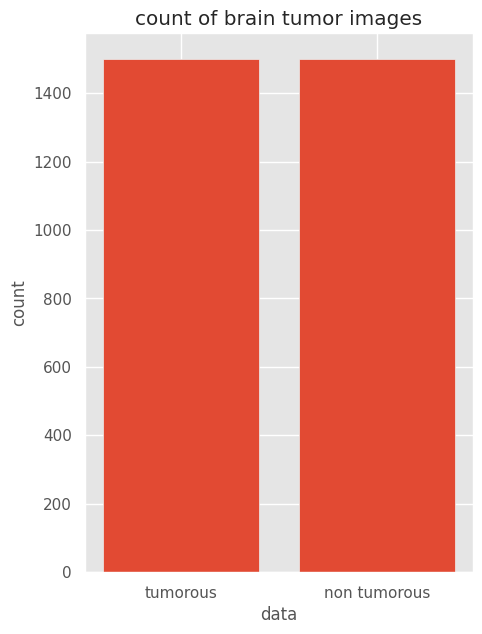

In [ ]:
data={"tumorous":yes_number, "non tumorous": no_number}
typx= data.keys()
values = data.values()
plt.figure(figsize=(5,7))

plt.bar(typx,values)
plt.xlabel("data")
plt.ylabel("count")
plt.title("count of brain tumor images")
plt.show()

data agumentation

In [ ]:
def timing(sec_elapsed):
  h = int(sec_elapsed /(60*60))
  m = int(sec_elapsed %(60*60/60))
  s = sec_elapsed % 60
  return f"{h}:{m}:{s}"
# how log it take to make images

In [ ]:
def agumented_data(file_dir,n_generated_samples, save_to_dir):
  data_gen = ImageDataGenerator(rotation_range=20,
                                width_shift_range=0.3,
                                height_shift_range=0.3,
                                shear_range=0.3,
                                brightness_range=(0.3, 1.0),
                                horizontal_flip=True,
                                vertical_flip=True,
                                fill_mode='nearest')
  for filename in os.listdir(file_dir):
    image = cv2.imread(file_dir + '/' + filename)
    image = image.reshape((1,)+image.shape)
    save_prefix = 'aug_' + filename[:-4]
    i=0
    for batch in data_gen.flow(x=image, batch_size = 1, save_to_dir=save_to_dir, save_prefix=save_prefix, save_format="jpg" ):
      i+=1
      if i >n_generated_samples:
        break
# n_generated_samples : number of samples per image

In [ ]:
import time
start_time = time.time()

os.makedirs('augmented_data/yes', exist_ok=True)
os.makedirs('augmented_data/no', exist_ok=True)

yes_path = '/content/yes'
no_path = '/content/no'
augmented_data_path = 'augmented_data/'

agumented_data(file_dir = yes_path, n_generated_samples=5, save_to_dir=augmented_data_path+'yes')
agumented_data(file_dir = no_path, n_generated_samples=5, save_to_dir=augmented_data_path+'no')

end_time = time.time()
execution_time = end_time - start_time
print(timing(execution_time))

0:12:12.515413761138916


In [ ]:
def data_summary(main_path):
  yes_path= '/content/augmented_data/yes'
  no_path='/content/augmented_data/no'

  n_pos = len(os.listdir(yes_path))
  n_neg = len(os.listdir(no_path))

  n = (n_pos+n_neg)

  pos_perc= (n_pos*100)/n
  neg_perc= (n_neg*100)/n

  print(f"Number of sample: {n} \n ")
  print(f"{n_pos} Number of positive sample in percentage: {pos_perc}% \n")
  print(f"{n_neg} Number of negative sample in percentage: {neg_perc}% \n")

In [ ]:
data_summary("/content/augmented_data")

Number of sample: 17993 
 
8996 Number of positive sample in percentage: 49.99722114155505% 

8997 Number of negative sample in percentage: 50.00277885844495% 



In [ ]:
list_y = os.listdir("/content/augmented_data/yes")
yes_number = len(list_y)
print(f"number of images in Yes folder {yes_number}")

list_n = os.listdir("/content/augmented_data/no")
no_number =  len(list_n)
print(f"number of images in No folder {no_number}")

number of images in Yes folder 8996
number of images in No folder 8997


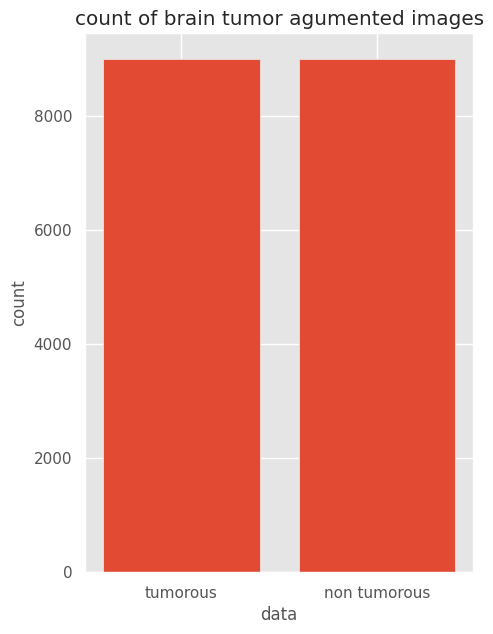

In [ ]:
data={"tumorous":yes_number, "non tumorous": no_number}
typx= data.keys()
values = data.values()
plt.figure(figsize=(5,7))

plt.bar(typx,values)
plt.xlabel("data")
plt.ylabel("count")
plt.title("count of brain tumor agumented images")
plt.show()

## data preprocessing

In [ ]:
# Convert BGR TO GRAY
# GaussianBlur
# Threshold
# Erode
# Dilate
# Find Contours

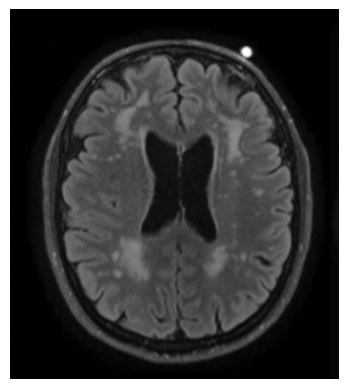

In [ ]:
img = plt.imread('/content/no/N_10.jpg')
plt.imshow(img)
plt.axis("off")
plt.show()

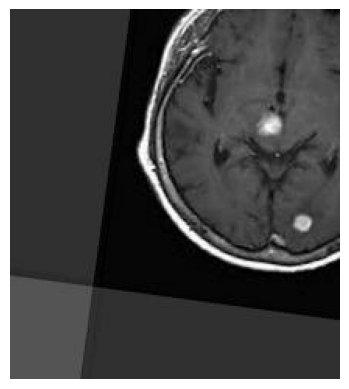

In [ ]:
img = plt.imread('/content/augmented_data/no/aug_N_1000_0_1487.jpg')
plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
# emove the black noise (the empty space around the skull)
import imutils
def crop_brain_tumor(image, plot=False):
  gray= cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
  gray = cv2.GaussianBlur(gray,(5,5),0) # remove noise

  # Isolating the Brain
  thes = cv2.threshold(gray, 45,255, cv2.THRESH_BINARY)[1] # Any pixel darker than 45 turned to 0 (black) ,anything brighter is turned to 255

  # erode: perform erosion--> A white pixel only stays white if all the pixels under that kernel are white.
  # If even one is black, the pixel turns black.to remove white noise
  thes = cv2.erode(thes, None, iterations=2)

  # dilate: perform Dilation A black pixel turns white if at least one pixel under the kernel is white
  thes = cv2.dilate(thes,None, iterations=2)

  # Finding the Contours
  cuts = cv2.findContours(thes.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
  # cv2.RETR_EXTERNAL: Only retrieves the outermost outlines (the skull/brain boundary)
  # cv2.CHAIN_APPROX_SIMPLE : Removes redundant points (like points along a straight line)
  cuts = imutils.grab_contours(cuts)
  if not cuts:
        return image
  c = max(cuts, key=cv2.contourArea) # get the max area which is the brain

  extLeft = tuple(c[c[:,:,0].argmin()][0])
  extRight = tuple(c[c[:,:,0].argmax()][0])
  extTop = tuple(c[c[:,:,1].argmin()][0])
  extBot = tuple(c[c[:,:,1].argmax()][0])

 # cutting
  new_image = image[extTop[1]:extBot[1], extLeft[0]:extRight[0]]

  if plot:
        plt.figure(figsize=(10, 5))
        plt.subplot(1, 2, 1)
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)) # Convert BGR to RGB for correct colors in plot
        plt.title('Original Image')
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(cv2.cvtColor(new_image, cv2.COLOR_BGR2RGB))
        plt.title('Cropped Image')
        plt.axis("off")
        plt.show()
  return new_image

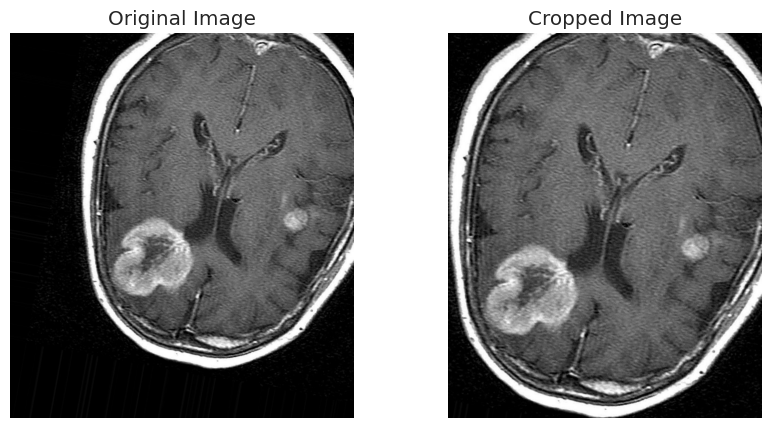

array([[[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [ 7,  7,  7],
        [ 3,  3,  3],
        [ 3,  3,  3]],

       [[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [ 9,  9,  9],
        [ 9,  9,  9],
        [ 9,  9,  9]],

       [[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [14, 14, 14],
        [ 8,  8,  8],
        [ 8,  8,  8]],

       ...,

       [[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [ 7,  7,  7],
        [10, 10, 10],
        [12, 12, 12]],

       [[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [ 6,  6,  6],
        [11, 11, 11],
        [11, 11, 11]],

       [[ 0,  0,  0],
        [ 0,  0,  0],
        [ 0,  0,  0],
        ...,
        [ 5,  5,  5],
        [ 7,  7,  7],
        [ 6,  6,  6]]], dtype=uint8)

In [ ]:
img = cv2.imread('/content/augmented_data/yes/aug_Y_1000_0_170.jpg')
crop_brain_tumor(img, True)

In [ ]:
folder1 = '/content/augmented_data/no'
folder2 = '/content/augmented_data/yes'

for filename in os.listdir(folder1):
    img = cv2.imread(os.path.join(folder1, filename))
    img = crop_brain_tumor(img, False)
    cv2.imwrite(os.path.join(folder1, filename), img)
for filename in os.listdir(folder2):
    img = cv2.imread(os.path.join(folder2, filename))
    img = crop_brain_tumor(img, False)
    cv2.imwrite(os.path.join(folder2, filename), img)

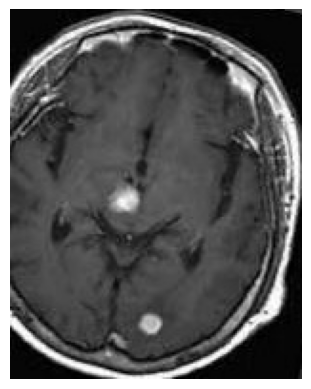

In [ ]:
img = plt.imread('/content/augmented_data/no/aug_N_1000_0_3486.jpg')
plt.imshow(img)
plt.axis("off")
plt.show()

## image loading

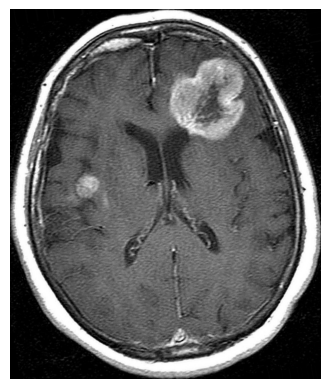

In [ ]:
img = plt.imread('/content/augmented_data/yes/aug_Y_1000_0_5229.jpg')
plt.imshow(img)
plt.axis('off')
plt.show()

In [ ]:
def load_data(dir_list, image_size):
  x=[]
  y=[]
  image_width, image_height= image_size

  for directory in dir_list:
    for filename in os.listdir(directory):
      image = cv2.imread(directory+'/'+filename)
      image = cv2.resize(image, dsize=(image_width, image_height), interpolation=cv2.INTER_CUBIC)
      image = (image/255.00).astype('float16')
      x.append(image)
      if directory[-3:]=='yes':
        y.append(1)
      else:
        y.append(0)
  x = np.array(x, dtype='float16')
  y = np.array(y)
  x,y = shuffle(x,y)
  print(f"Number of example is : {len(x)}")
  print(f"X SHAPE is : {x.shape}")
  print(f"y SHAPE is : {y.shape}")
  return x,y

In [ ]:
augmented_path = 'augmented_data/'
augmeneted_yes = augmented_path + 'yes'
augmeneted_no = augmented_path + 'no'

IMAGE_WIDTH, IMAGE_HEIGHT = (128,128)

x,y = load_data([augmeneted_yes, augmeneted_no], (IMAGE_WIDTH, IMAGE_HEIGHT))

Number of example is : 17993
X SHAPE is : (17993, 128, 128, 3)
y SHAPE is : (17993,)


## data splitting

In [ ]:
if not os.path.isdir('tumorous_and_nontumorous'):
  base_dir = 'tumorous_and_nontumorous'
  os.mkdir(base_dir)

In [ ]:
if not os.path.isdir('tumorous_and_nontumorous/train'):
    train_dir = os.path.join(base_dir , 'train')
    os.mkdir(train_dir)
if not os.path.isdir('tumorous_and_nontumorous/test'):
    test_dir = os.path.join(base_dir , 'test')
    os.mkdir(test_dir)
if not os.path.isdir('tumorous_and_nontumorous/valid'):
    valid_dir = os.path.join(base_dir , 'valid')
    os.mkdir(valid_dir)

In [ ]:
if not os.path.isdir('tumorous_and_nontumorous/train/tumorous'):
    infected_train_dir = os.path.join(train_dir, 'tumorous')
    os.mkdir(infected_train_dir)
if not os.path.isdir('tumorous_and_nontumorous/test/tumorous'):
    infected_test_dir = os.path.join(test_dir, 'tumorous')
    os.mkdir(infected_test_dir)
if not os.path.isdir('tumorous_and_nontumorous/valid/tumorous'):
    infected_valid_dir = os.path.join(valid_dir, 'tumorous')
    os.mkdir(infected_valid_dir)

In [ ]:
if not os.path.isdir('tumorous_and_nontumorous/train/nontumorous'):
    healthy_train_dir = os.path.join(train_dir, 'nontumorous')
    os.mkdir(healthy_train_dir)
if not os.path.isdir('tumorous_and_nontumorous/test/nontumorous'):
    healthy_test_dir = os.path.join(test_dir, 'nontumorous')
    os.mkdir(healthy_test_dir)
if not os.path.isdir('tumorous_and_nontumorous/valid/nontumorous'):
    healthy_valid_dir = os.path.join(valid_dir, 'nontumorous')
    os.mkdir(healthy_valid_dir)

In [ ]:
original_dataset_tumorours = os.path.join('augmented_data','yes/')
original_dataset_nontumorours = os.path.join('augmented_data','no/')

In [ ]:
len(os.listdir('augmented_data/yes/'))

8996

In [ ]:
len(os.listdir('augmented_data/no/'))

8997

In [ ]:
files = os.listdir('augmented_data/yes/')
fnames = []
for i in range(0,7200):
    fnames.append(files[i])
for fname in fnames:
    src = os.path.join(original_dataset_tumorours, fname)
    dst = os.path.join(infected_train_dir, fname)
    shutil.copyfile(src, dst)

In [ ]:
files = os.listdir('augmented_data/yes/')
fnames = []
for i in range(7200,8100):
    fnames.append(files[i])
for fname in fnames:
    src = os.path.join(original_dataset_tumorours, fname)
    dst = os.path.join(infected_test_dir, fname)
    shutil.copyfile(src, dst)

In [ ]:
files = os.listdir('augmented_data/yes/')
fnames = []
for i in range(8100,8996):
    fnames.append(files[i])
for fname in fnames:
    src = os.path.join(original_dataset_tumorours, fname)
    dst = os.path.join(infected_valid_dir, fname)
    shutil.copyfile(src, dst)

In [ ]:
files = os.listdir('augmented_data/no/')
fnames = []
for i in range(0,7200):
    fnames.append(files[i])
for fname in fnames:
    src = os.path.join(original_dataset_nontumorours, fname)
    dst = os.path.join(healthy_train_dir, fname)
    shutil.copyfile(src, dst)

In [ ]:
files = os.listdir('augmented_data/no/')
fnames = []
for i in range(7200,8100):
    fnames.append(files[i])
for fname in fnames:
    src = os.path.join(original_dataset_nontumorours, fname)
    dst = os.path.join(healthy_test_dir, fname)
    shutil.copyfile(src, dst)

In [ ]:
files = os.listdir('augmented_data/no/')
fnames = []
for i in range(8100,8997):
    fnames.append(files[i])
for fname in fnames:
    src = os.path.join(original_dataset_nontumorours, fname)
    dst = os.path.join(healthy_valid_dir, fname)
    shutil.copyfile(src, dst)

In [ ]:
len(os.listdir('/content/tumorous_and_nontumorous/train/nontumorous'))

7200

## Building model

In [ ]:
train_datagen = ImageDataGenerator(rescale = 1./255,
                  horizontal_flip=0.4,
                  vertical_flip=0.4,
                  rotation_range=40,
                  shear_range=0.2,
                  width_shift_range=0.4,
                  height_shift_range=0.4,
                  fill_mode='nearest')
test_data_gen = ImageDataGenerator(rescale=1.0/255)
valid_data_gen = ImageDataGenerator(rescale=1.0/255)

In [ ]:
train_generator = train_datagen.flow_from_directory('/content/tumorous_and_nontumorous/train/',
                                                    batch_size=32,
                                                    target_size=(224,224),
                                                    class_mode='categorical',
                                                    shuffle=True, seed = 42, color_mode = 'rgb')

Found 14400 images belonging to 2 classes.


In [ ]:
test_generator = train_datagen.flow_from_directory('/content/tumorous_and_nontumorous/test/',
                                                   batch_size=32,
                                                   target_size=(224,224),
                                                   class_mode='categorical',
                                                   shuffle=True, seed = 42, color_mode = 'rgb')

Found 1800 images belonging to 2 classes.


In [ ]:
valid_generator = train_datagen.flow_from_directory('/content/tumorous_and_nontumorous/valid/',
                                                    batch_size=32,
                                                    target_size=(224,224),
                                                    class_mode='categorical',
                                                    shuffle=True, seed = 42, color_mode = 'rgb')

Found 1793 images belonging to 2 classes.


In [ ]:
class_labels = train_generator.class_indices
class_name = {value: key for (key,value) in class_labels.items()}

In [ ]:
class_name

{0: 'nontumorous', 1: 'tumorous'}

In [ ]:
base_model = VGG19(input_shape = (224,224,3), include_top=False, weights='imagenet')

for layer in base_model.layers:
    layer.trainable=False

x=base_model.output
flat = Flatten()(x)

class_1 = Dense(4608, activation = 'relu')(flat)
drop_out = Dropout(0.2)(class_1)
class_2 = Dense(1152, activation = 'relu')(drop_out)
output = Dense(2, activation = 'softmax')(class_2)

model_01 = Model(base_model.input, output)
model_01.summary()

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4608)           │   115,610,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4608)           │             

 Total params: 140,946,370 (537.67 MB)

 Trainable params: 120,921,986 (461.28 MB)

 Non-trainable params: 20,024,384 (76.39 MB)

In [ ]:
# callback
filepath = model_01.save('brain_tumor_model.keras')
es = EarlyStopping(monitor='val_loss', verbose = 1, mode='min',patience=4)
cp = ModelCheckpoint(filepath, monitor='val_loss', verbose = 1, save_best_only=True, save_weights_only=False, mode='auto',save_freq='epoch')
lrr = ReduceLROnPlateau(monitor='val_accuracy', patience=3, verbose = 1, factor = 0.5, min_lr = 0.0001, mode='max')

In [ ]:
sgd = SGD(learning_rate=0.0001, momentum = 0.9, nesterov = True)
model_01.compile(loss='categorical_crossentropy', optimizer = sgd, metrics=['accuracy'])

In [ ]:
history_01 = model_01.fit(train_generator, steps_per_epoch=10, epochs = 10, callbacks=[es,cp,lrr], validation_data=valid_generator)

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 457ms/step - accuracy: 0.5333 - loss: 0.6966
Epoch 1: val_loss improved from None to 0.69408, saving model to model.h5



Epoch 1: finished saving model to model.h5
10/10 ━━━━━━━━━━━━━━━━━━━━ 42s 5s/step - accuracy: 0.5375 - loss: 0.7139 - val_accuracy: 0.5477 - val_loss: 0.6941 - learning_rate: 1.0000e-04
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 530ms/step - accuracy: 0.5477 - loss: 0.7296
Epoch 2: val_loss did not improve from 0.69408
10/10 ━━━━━━━━━━━━━━━━━━━━ 34s 4s/step - accuracy: 0.5437 - loss: 0.7188 - val_accuracy: 0.5231 - val_loss: 0.7193 - learning_rate: 1.0000e-04
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 353ms/step - accuracy: 0.5568 - loss: 0.6965
Epoch 3: val_loss improved from 0.69408 to 0.66239, saving model to model.h5



Epoch 3: finished saving model to model.h5
10/10 ━━━━━━━━━━━━━━━━━━━━ 42s 5s/step - accuracy: 0.5562 - loss: 0.6924 - val_accuracy: 0.6057 - val_loss: 0.6624 - learning_rate: 1.0000e-04
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 279ms/step - accuracy: 0.5651 - loss: 0.6652
Epoch 4: val_loss did not improve from 0.66239
10/10 ━━━━━━━━━━━━━━━━━━━━ 33s 4s/step - accuracy: 0.5500 - loss: 0.6802 - val_accuracy: 0.5973 - val_loss: 0.6666 - learning_rate: 1.0000e-04
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 279ms/step - accuracy: 0.5417 - loss: 0.7031
Epoch 5: val_loss improved from 0.66239 to 0.65811, saving model to model.h5



Epoch 5: finished saving model to model.h5
10/10 ━━━━━━━━━━━━━━━━━━━━ 44s 5s/step - accuracy: 0.5469 - loss: 0.6911 - val_accuracy: 0.6007 - val_loss: 0.6581 - learning_rate: 1.0000e-04
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 263ms/step - accuracy: 0.5718 - loss: 0.6793
Epoch 6: val_loss improved from 0.65811 to 0.64123, saving model to model.h5



Epoch 6: finished saving model to model.h5
10/10 ━━━━━━━━━━━━━━━━━━━━ 46s 5s/step - accuracy: 0.5688 - loss: 0.6807 - val_accuracy: 0.6347 - val_loss: 0.6412 - learning_rate: 1.0000e-04
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 264ms/step - accuracy: 0.5718 - loss: 0.6742
Epoch 7: val_loss improved from 0.64123 to 0.63537, saving model to model.h5



Epoch 7: finished saving model to model.h5
10/10 ━━━━━━━━━━━━━━━━━━━━ 38s 4s/step - accuracy: 0.5688 - loss: 0.6838 - val_accuracy: 0.6364 - val_loss: 0.6354 - learning_rate: 1.0000e-04
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 268ms/step - accuracy: 0.5758 - loss: 0.6827
Epoch 8: val_loss improved from 0.63537 to 0.62462, saving model to model.h5



Epoch 8: finished saving model to model.h5
10/10 ━━━━━━━━━━━━━━━━━━━━ 40s 4s/step - accuracy: 0.5969 - loss: 0.6692 - val_accuracy: 0.6553 - val_loss: 0.6246 - learning_rate: 1.0000e-04
Epoch 9/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 270ms/step - accuracy: 0.6364 - loss: 0.6371
Epoch 9: val_loss did not improve from 0.62462
10/10 ━━━━━━━━━━━━━━━━━━━━ 32s 4s/step - accuracy: 0.6344 - loss: 0.6299 - val_accuracy: 0.5148 - val_loss: 0.7405 - learning_rate: 1.0000e-04
Epoch 10/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - accuracy: 0.6210 - loss: 0.6324
Epoch 10: val_loss improved from 0.62462 to 0.62257, saving model to model.h5



Epoch 10: finished saving model to model.h5
10/10 ━━━━━━━━━━━━━━━━━━━━ 40s 4s/step - accuracy: 0.6344 - loss: 0.6151 - val_accuracy: 0.6704 - val_loss: 0.6226 - learning_rate: 1.0000e-04


In [ ]:
if not os.path.isdir('model_weights/'):
    os.mkdir('model_weights/')
model_01.save_weights(filepath="model_weights/vgg19_model_01.weights.keras", overwrite=True)

#if not os.path.isdir('models/'):
    #os.mkdir('models/')

# Save the WHOLE model (architecture + weights + optimizer state)
#model_01.save("models/vgg19_full_model.keras")

In [ ]:
model_01.load_weights("/content/model_weights/vgg19_model_01.weights.keras")
vgg_val_eval_01 = model_01.evaluate(valid_generator)
vgg_test_eval_01 = model_01.evaluate(test_generator)

57/57 ━━━━━━━━━━━━━━━━━━━━ 29s 506ms/step - accuracy: 0.6475 - loss: 0.6252
57/57 ━━━━━━━━━━━━━━━━━━━━ 34s 603ms/step - accuracy: 0.6506 - loss: 0.6346


In [ ]:
print(f'Validation Loss: {vgg_val_eval_01[0]}')
print(f'Validation Acc: {vgg_val_eval_01[1]}')
print(f'Testing Loss: {vgg_test_eval_01[0]}')
print(f'Testing Acc: {vgg_test_eval_01[1]}')

Validation Loss: 0.6252425909042358
Validation Acc: 0.6475180983543396
Testing Loss: 0.634640634059906
Testing Acc: 0.6505555510520935


In [ ]:
filenames = test_generator.filenames
nb_sample = len(filenames)

vgg_prediction_01 = model_01.predict(test_generator, steps=nb_sample, verbose = 1)
y_pred = np.argmax(vgg_prediction_01, axis=1)

1800/1800 ━━━━━━━━━━━━━━━━━━━━ 31s 16ms/step   


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


In [ ]:
base_model = VGG19(include_top=False, input_shape=(224,224,3))
base_model_layer_names = [layer.name for layer in base_model.layers]

x=base_model.output
flat = GlobalAveragePooling2D()(x)

class_1 = Dense(1024, activation = 'relu')(flat)
drop_out = Dropout(0.4)(class_1)
class_2 = Dense(512, activation='relu')(drop_out)
drop_out2 = Dropout(0.3)(class_2)
output = Dense(2, activation = 'softmax')(drop_out2)

model_02 = Model(base_model.inputs, output)
# model_02.load_weights('/content/model_weights/vgg19_model_01.weights.h5')

set_trainable=False
for layer in base_model.layers:
    if layer.name in ['block5_conv4','block5_conv3']:
        set_trainable=True
    if set_trainable:
        layer.trainable=True
    else:
        layer.trainable=False

print(model_02.summary())

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 21,075,522 (80.40 MB)

 Trainable params: 5,770,754 (22.01 MB)

 Non-trainable params: 15,304,768 (58.38 MB)

None


In [ ]:
sgd = SGD(learning_rate=0.01, momentum = 0.9, nesterov = True)
model_02.compile(loss='categorical_crossentropy', optimizer = sgd, metrics=['accuracy'])

In [ ]:
history_02 = model_02.fit(train_generator, epochs =20, callbacks=[es,cp,lrr], validation_data=valid_generator)

Epoch 1/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 511ms/step - accuracy: 0.7023 - loss: 0.5422
Epoch 1: val_loss improved from 0.62257 to 0.24690, saving model to model.h5



Epoch 1: finished saving model to model.h5
450/450 ━━━━━━━━━━━━━━━━━━━━ 268s 581ms/step - accuracy: 0.7908 - loss: 0.4300 - val_accuracy: 0.9052 - val_loss: 0.2469 - learning_rate: 0.0100
Epoch 2/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 510ms/step - accuracy: 0.8827 - loss: 0.2797
Epoch 2: val_loss did not improve from 0.24690
450/450 ━━━━━━━━━━━━━━━━━━━━ 258s 573ms/step - accuracy: 0.8851 - loss: 0.2705 - val_accuracy: 0.8673 - val_loss: 0.2967 - learning_rate: 0.0100
Epoch 3/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 508ms/step - accuracy: 0.9043 - loss: 0.2319
Epoch 3: val_loss improved from 0.24690 to 0.16862, saving model to model.h5



Epoch 3: finished saving model to model.h5
450/450 ━━━━━━━━━━━━━━━━━━━━ 257s 570ms/step - accuracy: 0.9099 - loss: 0.2213 - val_accuracy: 0.9336 - val_loss: 0.1686 - learning_rate: 0.0100
Epoch 4/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.9246 - loss: 0.1918
Epoch 4: val_loss improved from 0.16862 to 0.15182, saving model to model.h5



Epoch 4: finished saving model to model.h5
450/450 ━━━━━━━━━━━━━━━━━━━━ 257s 570ms/step - accuracy: 0.9264 - loss: 0.1841 - val_accuracy: 0.9437 - val_loss: 0.1518 - learning_rate: 0.0100
Epoch 5/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 504ms/step - accuracy: 0.9383 - loss: 0.1593
Epoch 5: val_loss improved from 0.15182 to 0.14384, saving model to model.h5



Epoch 5: finished saving model to model.h5
450/450 ━━━━━━━━━━━━━━━━━━━━ 255s 567ms/step - accuracy: 0.9385 - loss: 0.1559 - val_accuracy: 0.9481 - val_loss: 0.1438 - learning_rate: 0.0100
Epoch 6/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 505ms/step - accuracy: 0.9387 - loss: 0.1531
Epoch 6: val_loss improved from 0.14384 to 0.11671, saving model to model.h5


...


Epoch 9: finished saving model to model.h5
450/450 ━━━━━━━━━━━━━━━━━━━━ 259s 563ms/step - accuracy: 0.9581 - loss: 0.1069 - val_accuracy: 0.9699 - val_loss: 0.0903 - learning_rate: 0.0100
Epoch 10/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 504ms/step - accuracy: 0.9640 - loss: 0.0963
Epoch 10: val_loss improved from 0.09033 to 0.08817, saving model to model.h5



Epoch 10: finished saving model to model.h5
450/450 ━━━━━━━━━━━━━━━━━━━━ 254s 565ms/step - accuracy: 0.9607 - loss: 0.0998 - val_accuracy: 0.9649 - val_loss: 0.0882 - learning_rate: 0.0100
Epoch 11/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 504ms/step - accuracy: 0.9689 - loss: 0.0818
Epoch 11: val_loss did not improve from 0.08817
450/450 ━━━━━━━━━━━━━━━━━━━━ 255s 566ms/step - accuracy: 0.9671 - loss: 0.0871 - val_accuracy: 0.9615 - val_loss: 0.0950 - learning_rate: 0.0100
Epoch 12/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 503ms/step - accuracy: 0.9633 - loss: 0.0923
Epoch 12: val_loss did not improve from 0.08817

Epoch 12: ReduceLROnPlateau reducing learning rate to 0.004999999888241291.
450/450 ━━━━━━━━━━━━━━━━━━━━ 255s 567ms/step - accuracy: 0.9661 - loss: 0.0859 - val_accuracy: 0.9643 - val_loss: 0.0920 - learning_rate: 0.0100
Epoch 13/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.9733 - loss: 0.0763
Epoch 13: val_loss did not improve from 0.08817
450/450 ━━━━━━━━━━━━━━━━━━━━ 256


Epoch 14: finished saving model to model.h5
450/450 ━━━━━━━━━━━━━━━━━━━━ 257s 570ms/step - accuracy: 0.9772 - loss: 0.0619 - val_accuracy: 0.9716 - val_loss: 0.0736 - learning_rate: 0.0050
Epoch 15/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 508ms/step - accuracy: 0.9768 - loss: 0.0607
Epoch 15: val_loss improved from 0.07358 to 0.04804, saving model to model.h5



Epoch 15: finished saving model to model.h5
450/450 ━━━━━━━━━━━━━━━━━━━━ 257s 571ms/step - accuracy: 0.9772 - loss: 0.0597 - val_accuracy: 0.9805 - val_loss: 0.0480 - learning_rate: 0.0050
Epoch 16/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 511ms/step - accuracy: 0.9792 - loss: 0.0555
Epoch 16: val_loss did not improve from 0.04804
450/450 ━━━━━━━━━━━━━━━━━━━━ 258s 573ms/step - accuracy: 0.9792 - loss: 0.0570 - val_accuracy: 0.9788 - val_loss: 0.0608 - learning_rate: 0.0050
Epoch 17/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.9777 - loss: 0.0585
Epoch 17: val_loss did not improve from 0.04804
450/450 ━━━━━━━━━━━━━━━━━━━━ 256s 568ms/step - accuracy: 0.9785 - loss: 0.0571 - val_accuracy: 0.9799 - val_loss: 0.0516 - learning_rate: 0.0050
Epoch 18/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 503ms/step - accuracy: 0.9802 - loss: 0.0527
Epoch 18: val_loss did not improve from 0.04804

Epoch 18: ReduceLROnPlateau reducing learning rate to 0.0024999999441206455.
450/450 ━━━━━━━━━━━━━━━━━━━━ 25


Epoch 19: finished saving model to model.h5
450/450 ━━━━━━━━━━━━━━━━━━━━ 254s 565ms/step - accuracy: 0.9833 - loss: 0.0442 - val_accuracy: 0.9816 - val_loss: 0.0465 - learning_rate: 0.0025
Epoch 20/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 503ms/step - accuracy: 0.9834 - loss: 0.0435
Epoch 20: val_loss did not improve from 0.04650
450/450 ━━━━━━━━━━━━━━━━━━━━ 255s 567ms/step - accuracy: 0.9840 - loss: 0.0432 - val_accuracy: 0.9816 - val_loss: 0.0516 - learning_rate: 0.0025


In [ ]:
if not os.path.isdir('model_weights/'):
    os.mkdir('model_weights/')
model_02.save_weights(filepath="model_weights/vgg19_model_02.weights.h5", overwrite=True)

In [ ]:
model_02.load_weights("/content/model_weights/vgg19_model_02.weights.h5")
vgg_val_eval_02 = model_02.evaluate(valid_generator)
vgg_test_eval_02 = model_02.evaluate(test_generator)

57/57 ━━━━━━━━━━━━━━━━━━━━ 40s 694ms/step - accuracy: 0.9799 - loss: 0.0469
57/57 ━━━━━━━━━━━━━━━━━━━━ 40s 694ms/step - accuracy: 0.9806 - loss: 0.0457


In [ ]:
model_02.save('model_02.keras')